In [12]:

import pandas as pd
import os

file_path = r"C:\Users\lenovo\OneDrive\Desktop\data science\iris.csv"

print(os.path.exists(file_path))

df = pd.read_csv(file_path)

df.head()


True


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [10]:
# Import libraries
from sklearn.datasets import load_iris  #built in iris dataset load krwaya h 
from sklearn.model_selection import train_test_split #Divides the data into training and testing sets
from sklearn.naive_bayes import GaussianNB  #for naive bayes classification algorithm
from sklearn.metrics import accuracy_score, classification_report#Calculates percentage of correctpredictions Gives more detailed performance measurements

# Load dataset
iris = load_iris()
X = iris.data  #for input features like sepla length,width and petal length width
y = iris.target  #extracts the correct species labels.

# Split into training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#X_train: measurements used for learning.
#X_test: measurements used for testing.
#y_train: correct species labels for the training flowers.
#y_test: correct species labels for the test flowers.
#test_size=0.2 means 20% of the data is reserved for testing.
#random_state=42 It makes the random split reproducible. If you run the same code with the same data and settings, you get the same split.

# Initialize and train model
model = GaussianNB()#model = GaussianNB() → creates the model.
model.fit(X_train, y_train)#model.fit(...) → trains the model.


# Predict
predictions = model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, predictions))
#Accuracy measures the proportion of test predictions that are correct.
#Accuracy=Correct predictions/Total predictions
print(classification_report(y_test, predictions))
#The classification_report() function displays four important measurements:
#Term	Simple meaning
#Precision	Of the flowers predicted as a particular species, how many were actually that species?
#Recall	Of all the actual flowers of a particular species, how many did the model identify correctly?
#F1-score	A combined measure of precision and recall
#Support	Number of actual test examples belonging to that species

Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [9]:
#EDA OF IRIS : 
import pandas as pd #for handling datasets
import numpy as np #for numerical computing
import matplotlib.pyplot as plt #for plots
import seaborn as sns  #for statistical visualizing

file_path = r"C:\Users\lenovo\OneDrive\Desktop\data science\iris.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [15]:
%pip install seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [8]:
#step 1 : display the dataset
df.head() #for first five rows
df.tail() #for last five rows

,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [18]:
#Step 2 — Find the dataset's dimensions
print("Rows and columns:", df.shape)
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

Rows and columns: (150, 5)
Total rows: 150
Total columns: 5


In [19]:
#Step 3 — Check the column names
print(df.columns.tolist())

['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


In [20]:
#step 4 — Understand data types
df.info()
#This shows:
# Number of entries.
# Column names.
# Data types, such as integers, decimals, and text.
# Non-null counts, which help identify possible missing values.

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


In [21]:
#Step 5 — Generate statistical summaries
df.describe()
#count	Number of non-missing numeric values
#mean	Average
#std	Standard deviation, showing how spread out values are
#min	Smallest value
#25%	First quartile
#50%	Median
#75%	Third quartile
#max	Largest value

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [23]:
#step 6 calculating missing values:
print(df.isnull().sum())
#To calculate the percentage of missing values:
missing_percentage = df.isnull().mean() * 100
print(missing_percentage)

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
sepal_length    0.0
sepal_width     0.0
petal_length    0.0
petal_width     0.0
species         0.0
dtype: float64


In [7]:
#Step 7 — Find duplicate rows
df_clean = df.drop_duplicates()

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (150, 5)
Cleaned shape: (147, 5)


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


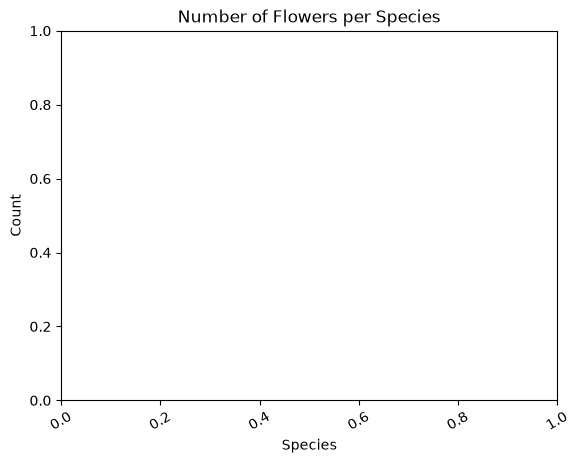

In [10]:
#Step 8 — Check the number of flowers in each species
print(df["species"].value_counts()) #tells you how many records belong to each species.
#if we visualize it : sns.countplot(data=df, x="species")

plt.title("Number of Flowers per Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.show()

In [11]:
#Step 9 — Explore individual columns
print("Average sepal length:",
      df["sepal_length"].mean())

print("Median petal length:",
      df["petal_length"].median())

print("Maximum petal width:",
      df["petal_width"].max())

print("Minimum petal width:",
      df["petal_width"].min())

Average sepal length: 5.843333333333334
Median petal length: 4.35
Maximum petal width: 2.5
Minimum petal width: 0.1


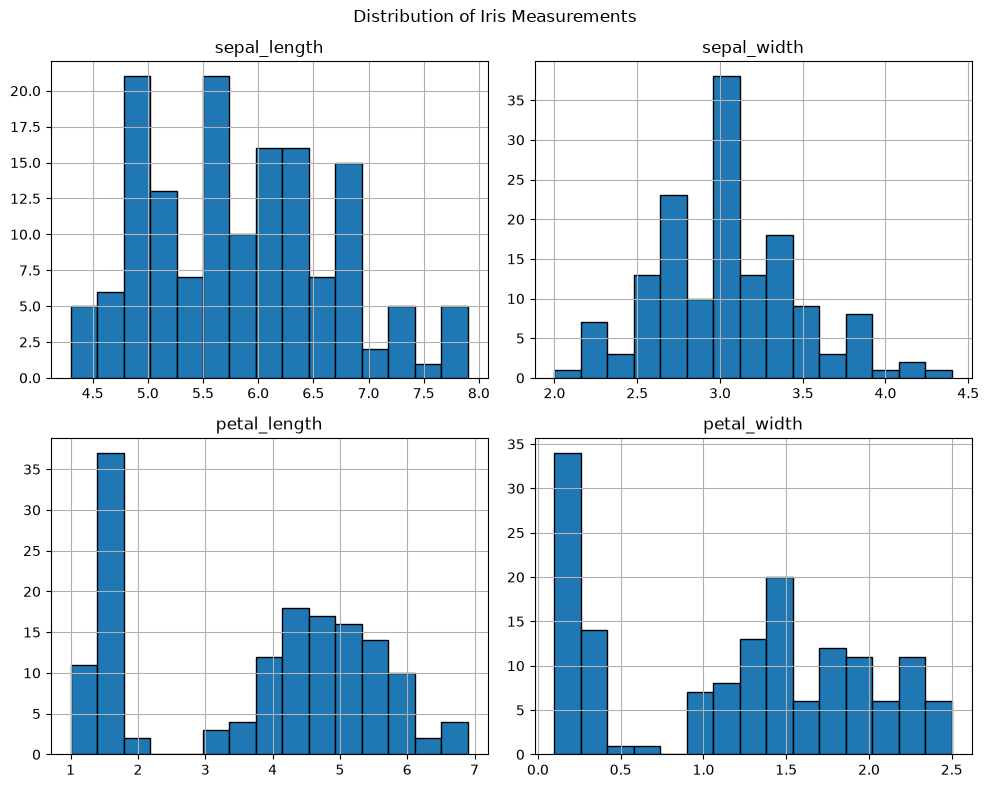

In [13]:
#Step 10 — Plot histograms
#A histogram shows how frequently different ranges of values occur.
df.select_dtypes(include="number").hist(
    figsize=(10, 8),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Iris Measurements")
plt.tight_layout()
plt.savefig("iris_histograms.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
import os
print(os.getcwd())

C:\Users\lenovo


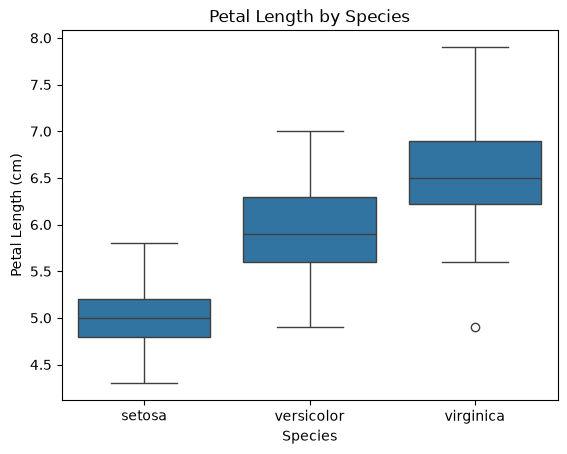

In [16]:
#Step 11 — Compare species using box plots
#A box plot helps you compare the distribution of measurements and identify potential outliers.
sns.boxplot(data=df, x="species", y="sepal_length")

plt.title("Petal Length by Species")
plt.xlabel("Species")
plt.ylabel("Petal Length (cm)")
plt.show()
#Which species tends to have longer petals? Are there any unusual values?

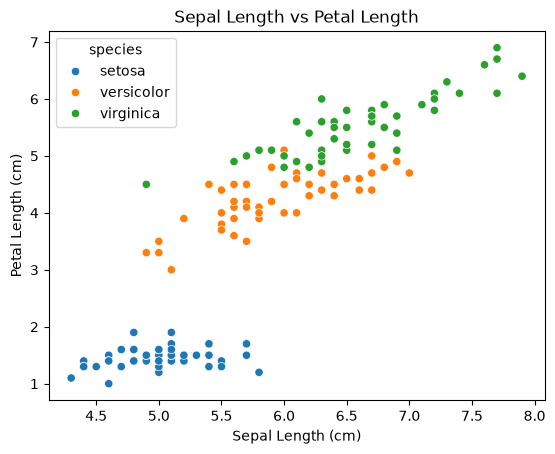

In [17]:
#Step 12 — Create a scatter plot
#A scatter plot helps you examine the relationship between two measurements.
sns.scatterplot(
    data=df,
    x="sepal_length",
    y="petal_length",
    hue="species"
)

plt.title("Sepal Length vs Petal Length")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.show()

              sepal_length  sepal_width  petal_length  petal_width
sepal_length      1.000000    -0.109369      0.871754     0.817954
sepal_width      -0.109369     1.000000     -0.420516    -0.356544
petal_length      0.871754    -0.420516      1.000000     0.962757
petal_width       0.817954    -0.356544      0.962757     1.000000


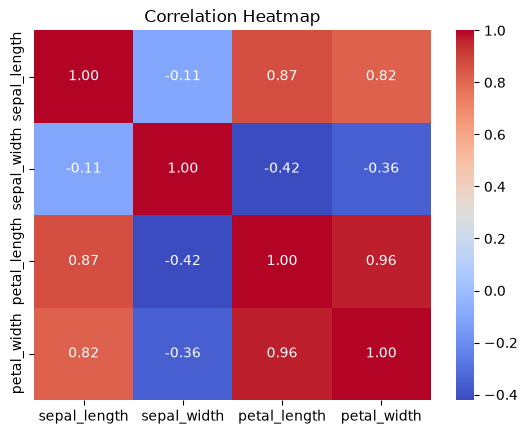

In [19]:
#Step 13 — Calculate correlations
#Correlation measures how strongly two numerical variables move together in a linear relationship.
numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()
print(correlation)
#to visualisze it as heatmap 
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [22]:
#Step 14 — Compare average measurements by species
df.groupby("species").mean(numeric_only=True)
#It calculates the average of every numeric column for each species.

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.418,1.464,0.244
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


In [23]:
#step 15 mean , median , std (statistical analysis)
df.groupby("species").agg(["mean", "median", "std"])

sepal_length                  sepal_width                   \
                   mean median       std        mean median       std   
species                                                                 
setosa            5.006    5.0  0.352490       3.418    3.4  0.381024   
versicolor        5.936    5.9  0.516171       2.770    2.8  0.313798   
virginica         6.588    6.5  0.635880       2.974    3.0  0.322497   

           petal_length                  petal_width                   
                   mean median       std        mean median       std  
species                                                                
setosa            1.464   1.50  0.173511       0.244    0.2  0.107210  
versicolor        4.260   4.35  0.469911       1.326    1.3  0.197753  
virginica         5.552   5.55  0.551895       2.026    2.0  0.274650

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
Training samples: 120
Testing samples: 30
Model trained successfully!
Actual species:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa']

Predicted species:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' '

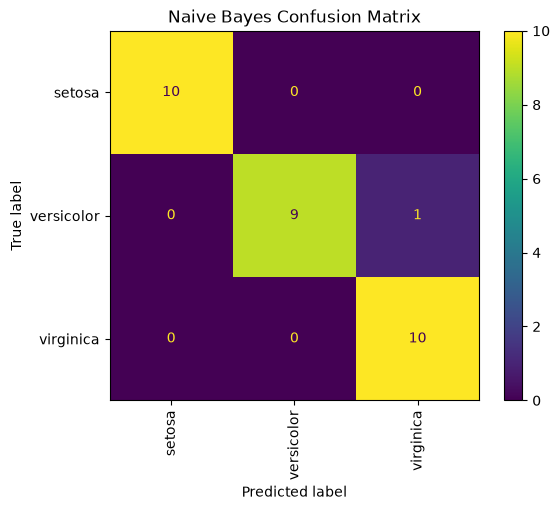

Predicted species: setosa


In [33]:
#APPLYING NAIVE BAYES 
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

#Check your dataset columns
print(df.head())
print(df.columns.tolist())

#PREPARE X AND Y ,X contains the information used to make predictions, while y contains the correct species labels the model will learn.
X = df[[
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]]

y = df["species"]

#SPLIT THE DATASET 
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, #20% FOR TESTING 
    random_state=42, #makes the split reproducible.
    stratify=y #helps preserve the proportions of the species in both sets.
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

#TRAIN THE NAIVE BAYES MODEL 
#We use Gaussian Naive Bayes because it models numerical features such as petal length and sepal width using Gaussian (normal)
#distributions within each class.
model = GaussianNB()
model.fit(X_train, y_train)
print("Model trained successfully!")

#MAKE PREDICTIONS
y_pred = model.predict(X_test) #Y_TEST CONTAINS ACTUAL SPECIES LABELS , Y_PRED CONTAINS SPECIES PREDICTED BY MODEL
print("Actual species:")
print(y_test.to_numpy())
print("\nPredicted species:")
print(y_pred)

#EVALUTE THE MODEL 
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy) #Overall proportion of correct predictions
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
#Precision	How often predictions for a species are correct
#Recall	How many actual flowers of a species the model identifies correctly
#F1-score	Balance between precision and recall
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:") #Shows correct and incorrect classifications by class
print(confusion_matrix(y_test, y_pred))
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation="vertical"
)

plt.title("Naive Bayes Confusion Matrix")
plt.show()

#PREDICT A NEW FLOWER 
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

prediction = model.predict(new_flower)

print("Predicted species:", prediction[0])
